## 1. Data Loading and Overview

In [1]:
from google.colab import files
uploaded = files.upload()


Saving _TB_Dataset_encode_clus.xlsx to _TB_Dataset_encode_clus.xlsx


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("_TB_Dataset_encode_clus.xlsx")

print(f"Number of records: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")
display(df.head())

Number of records: 25,239
Number of columns: 25


,BMI,Gender,Age,ICD10_Group_Chronic_Diseases,ICD10_Group_Lymph_Node_TB,ICD10_Group_Miliary_TB,ICD10_Group_Nervous_System_TB,ICD10_Group_Other_Extrapulmonary_TB,ICD10_Group_Other_Respiratory_TB,ICD10_Group_Pulmonary_TB,...,Take a Co-Trimoxazole,(TB F/U) follow up,position of TB,Chronic Kidney Disease,Chronic Obstructive Pulmonary Disease,Diabetes Mellitus,Liver Disease,AFB resulf of first month,Duration,result
0,15.23,0,68,0,0,0,0,0,0,1,...,0,1,1,0,0,0,0,3,1.0,เสียชีวิต
1,23.11,1,41,0,0,0,0,0,0,1,...,0,3,2,0,0,0,0,0,6.0,รักษาครบ
2,21.45,0,42,0,0,0,0,0,0,1,...,0,1,1,0,0,0,0,-1,6.0,รักษาครบ
3,17.57,1,45,0,0,0,0,0,0,1,...,0,3,1,0,0,1,0,2,6.0,รักษาหาย
4,19.12,0,21,0,0,0,0,0,0,1,...,0,2,1,0,0,0,0,2,6.0,รักษาหาย


## 2. Data Cleaning

In [4]:
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Count': missing_data,
    'Percentage (%)': missing_percent
}).sort_values(by='Missing Count', ascending=False)


print("--- Missing Values Report ---")
print(missing_report[missing_report['Missing Count'] > 0])

--- Missing Values Report ---
          Missing Count  Percentage (%)
Duration           1479        5.859979


In [5]:
def clean_data(df, name="Dataset"):
    print(f"--- Cleaning Report for: {name} ---")

    missing_rows = df.isnull().any(axis=1).sum()
    if missing_rows > 0:
        print(f"[!] Found {missing_rows} rows with missing values. Dropping them...")
        df = df.dropna()
    else:
        print("[✓] No missing values found.")

    constant_cols = [col for col in df.columns if df[col].nunique() <= 1]
    if len(constant_cols) > 0:
        print(f"[*] Removing {len(constant_cols)} constant columns: {constant_cols}")
        df = df.drop(columns=constant_cols)
    else:
        print("[✓] No constant columns to remove.")

    print(f"Final shape: {df.shape}\n")
    return df


In [6]:
dt_after_clean = clean_data(df)

--- Cleaning Report for: Dataset ---
[!] Found 1479 rows with missing values. Dropping them...
[✓] No constant columns to remove.
Final shape: (23760, 25)



In [7]:
dt_after_clean['result'].value_counts()

,count
result,
รักษาครบ,9570
รักษาหาย,8749
เสียชีวิต,2920
เปลี่ยนวินิจฉัย,1255
ขาดยา,725
โอนออก,283
RR/MDR ก่อนเดือนที่ 5,126
ล้มเหลว,75
กำลังรักษา,57


In [8]:
df_after_clean = dt_after_clean[~dt_after_clean['result'].isin(['โอนออก','กำลังรักษา'])]

In [9]:
print(df_after_clean['result'].value_counts())

result
รักษาครบ                 9570
รักษาหาย                 8749
เสียชีวิต                2920
เปลี่ยนวินิจฉัย          1255
ขาดยา                     725
RR/MDR ก่อนเดือนที่ 5     126
ล้มเหลว                    75
Name: count, dtype: int64


### Correlation Analysis

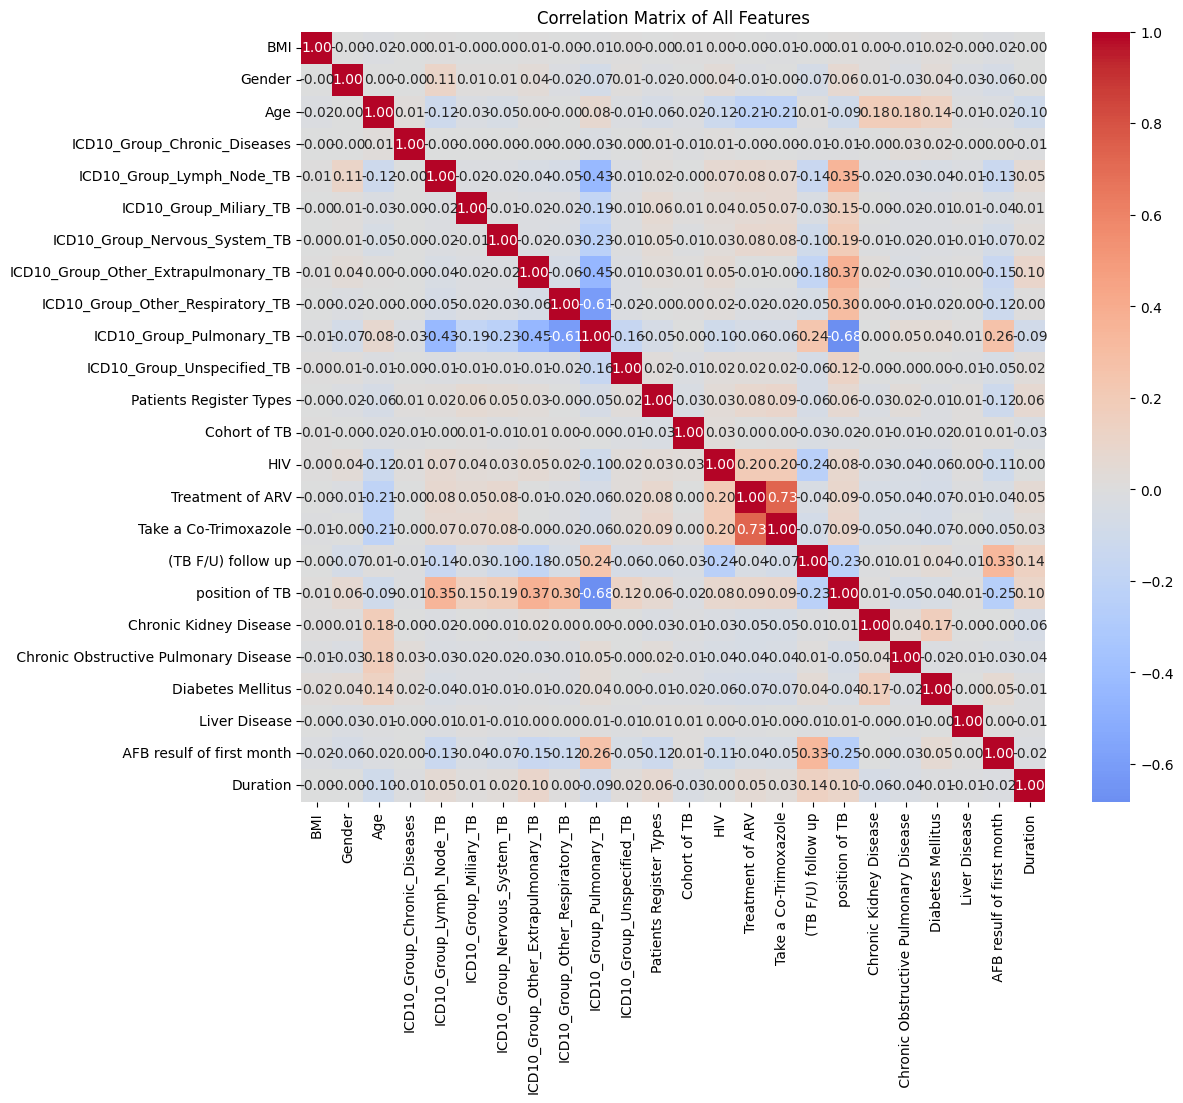

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numeric columns for correlation calculation
corr_matrix = dt_after_clean.select_dtypes(include=['number']).corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of All Features')
plt.show()

## 3. Target Construction

- `0`: Successful treatment outcomes
- `1`: Unsuccessful treatment outcomes


In [11]:
def create_target(x):

    if x in ['รักษาหาย', 'รักษาครบ']:
        return 0

    elif x in ['เสียชีวิต', 'ขาดยา', 'เปลี่ยนวินิจฉัย', 'ล้มเหลว', 'RR/MDR ก่อนเดือนที่ 5 ']:
        return 1

    else:
        return None

In [12]:
df_after_clean['target'] = df_after_clean['result'].apply(create_target)

df_after_clean = df_after_clean[df_after_clean['target'].notna()]

/tmp/ipykernel_545/2427547002.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_after_clean['target'] = df_after_clean['result'].apply(create_target)


## 4. Feature Selection

In [13]:
selected_columns = [('BMI', 'Gender', 'Age', 'ICD10_Group_Chronic_Diseases',
       'ICD10_Group_Lymph_Node_TB', 'ICD10_Group_Miliary_TB',
       'ICD10_Group_Nervous_System_TB', 'ICD10_Group_Other_Extrapulmonary_TB',
       'ICD10_Group_Other_Respiratory_TB', 'ICD10_Group_Pulmonary_TB',
       'ICD10_Group_Unspecified_TB', 'Patients Register Types', 'Cohort of TB',
       'HIV', 'Treatment of ARV', 'Take a Co-Trimoxazole',
       '(TB F/U) follow up', 'position of TB', 'Chronic Kidney Disease',
       ' Chronic Obstructive Pulmonary Disease', 'Diabetes Mellitus',
       'Liver Disease', ' AFB resulf of first month', 'Duration')]

In [14]:
X = df_after_clean[list(selected_columns[0])]
y = df_after_clean['target']

## 5. Train-Test Split

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

## 6. Model Training and Evaluation

### 6.1 XGBoost

In [19]:
from xgboost import XGBClassifier

best_xgb = XGBClassifier(
    objective='binary:logistic',
    scale_pos_weight=3.6821608040201004,
    random_state=42,
    subsample=0.9,
    n_estimators=300,
    max_depth=3,
    learning_rate=0.01,
    colsample_bytree=0.8
)

best_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.01, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, ...)

In [20]:
from sklearn.metrics import classification_report
y_pred_xgb_tuned = best_xgb.predict(X_test)
print(classification_report(y_test, y_pred_xgb_tuned))

              precision    recall  f1-score   support

         0.0       0.95      0.97      0.96      3664
         1.0       0.89      0.82      0.85       995

    accuracy                           0.94      4659
   macro avg       0.92      0.90      0.91      4659
weighted avg       0.94      0.94      0.94      4659



### 6.2 Random Forest

In [21]:
from sklearn.ensemble import RandomForestClassifier

best_rf = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_estimators=100,
    min_samples_split=2,
    min_samples_leaf=4,
    max_depth=5
)

best_rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=5, min_samples_leaf=4,
                       random_state=42)

In [22]:
y_pred_rf_tuned = best_rf.predict(X_test)
print(classification_report(y_test, y_pred_rf_tuned))

              precision    recall  f1-score   support

         0.0       0.95      0.97      0.96      3664
         1.0       0.88      0.82      0.85       995

    accuracy                           0.94      4659
   macro avg       0.92      0.90      0.91      4659
weighted avg       0.94      0.94      0.94      4659



### 6.3 CatBoost

In [23]:
!pip -q install catboost

from catboost import CatBoostClassifier

best_cat = CatBoostClassifier(
    auto_class_weights='Balanced',
    verbose=False,
    random_state=42,
    learning_rate=0.01,
    l2_leaf_reg=3,
    iterations=200,
    depth=10
)

best_cat.fit(X_train, y_train)

CatBoostClassifier(auto_class_weights='Balanced', depth=10, iterations=200, l2_leaf_reg=3, learning_rate=0.01, random_state=42, verbose=False)

In [24]:
y_pred_cat_tuned = best_cat.predict(X_test)
print(classification_report(y_test, y_pred_cat_tuned))

              precision    recall  f1-score   support

         0.0       0.95      0.97      0.96      3664
         1.0       0.89      0.82      0.85       995

    accuracy                           0.94      4659
   macro avg       0.92      0.90      0.91      4659
weighted avg       0.94      0.94      0.94      4659



### 6.4 Artificial Neural Network (ANN)

In [25]:
import random
import numpy as np
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [26]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_sm, y_train_sm = smote.fit_resample(
    X_train,
    y_train
)

In [27]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

model_ANN = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [28]:
model_ANN.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [29]:
model_ANN.fit(
    X_train_sm,
    y_train_sm,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    class_weight={0:1, 1:3}
)

Epoch 1/50
733/733 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.6954 - loss: 0.9245 - val_accuracy: 0.8286 - val_loss: 0.2293
Epoch 2/50
733/733 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8511 - loss: 0.6314 - val_accuracy: 0.8767 - val_loss: 0.1806
Epoch 3/50
733/733 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8544 - loss: 0.5889 - val_accuracy: 0.8717 - val_loss: 0.1894
Epoch 4/50
733/733 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8547 - loss: 0.5570 - val_accuracy: 0.9007 - val_loss: 0.1718
Epoch 5/50
733/733 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8611 - loss: 0.5333 - val_accuracy: 0.8942 - val_loss: 0.1779
Epoch 6/50
733/733 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8660 - loss: 0.5309 - val_accuracy: 0.9034 - val_loss: 0.1692
Epoch 7/50
733/733 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8698 - loss: 0.5099 - val_accuracy: 0.8953 - val_loss: 0.1672
Epoch 8/50
733/733 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8761 - loss: 0.4917 - val_accuracy:

In [ ]:
loss, acc = model_ANN.evaluate(X_test, y_test)

146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9015 - loss: 0.3098


In [30]:
y_prob = model_ANN.predict(X_test)
y_pred_ANN = (y_prob > 0.70).astype(int)

146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [31]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
print(confusion_matrix(y_test, y_pred_ANN))
print(classification_report(y_test, y_pred_ANN))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

[[3510  154]
 [ 174  821]]
              precision    recall  f1-score   support

         0.0       0.95      0.96      0.96      3664
         1.0       0.84      0.83      0.83       995

    accuracy                           0.93      4659
   macro avg       0.90      0.89      0.89      4659
weighted avg       0.93      0.93      0.93      4659

ROC-AUC: 0.9438443582541528


## 7. Model Performance Comparison

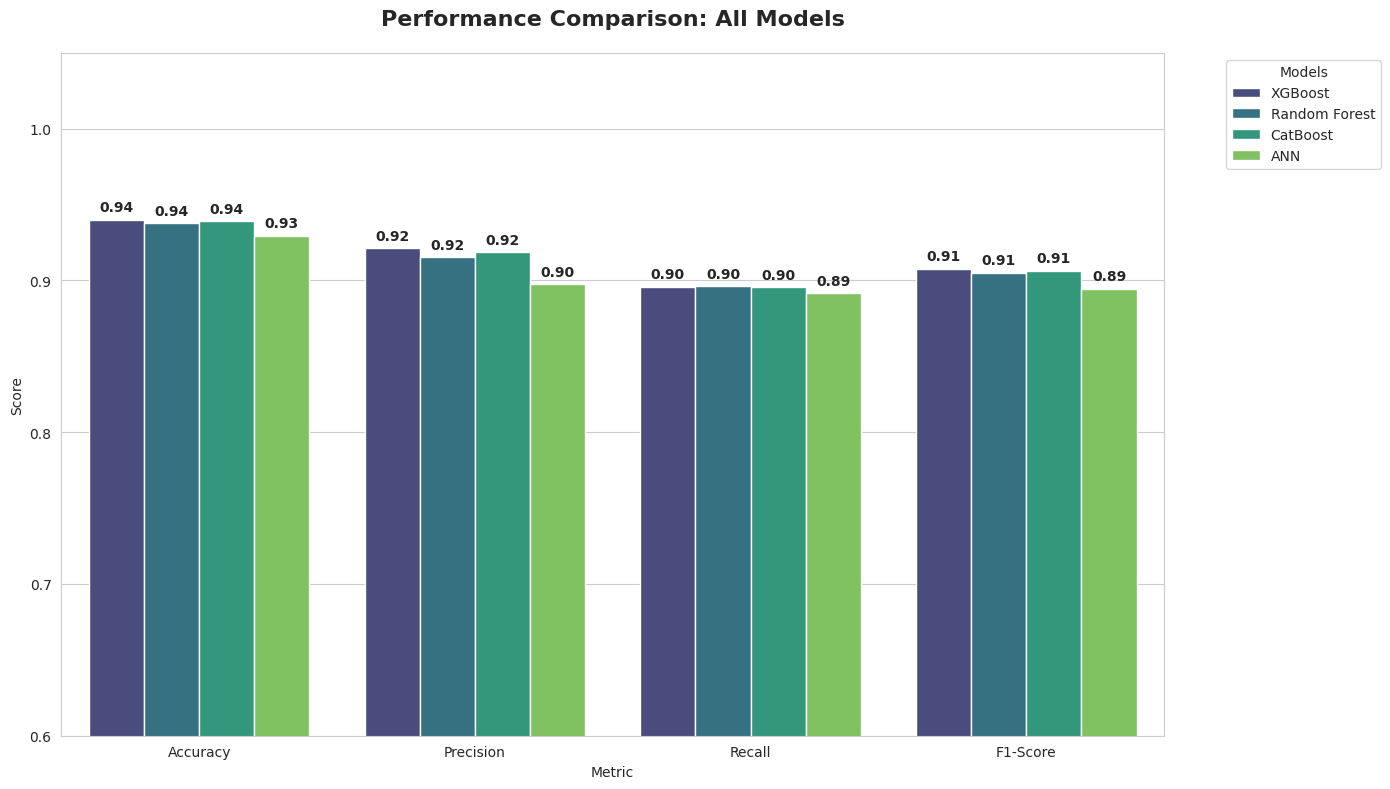


--- Summary Table ---
        Model  Accuracy  Precision   Recall  F1-Score
      XGBoost  0.939901   0.921317 0.895901  0.907803
Random Forest  0.937755   0.915289 0.896001  0.905171
     CatBoost  0.938828   0.918567 0.895585  0.906411
          ANN  0.929599   0.897410 0.891548  0.894432


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

# รวบรวมข้อมูล Prediction ของทุกโมเดล
models = {
    'XGBoost': y_pred_xgb_tuned,
    'Random Forest': y_pred_rf_tuned,
    'CatBoost': y_pred_cat_tuned,
    'ANN': y_pred_ANN
}

# วนลูปเพื่อดึงค่า Macro Avg (Precision, Recall, F1, Accuracy) ออกมาอัตโนมัติ
summary_list = []

for name, y_pred in models.items():
    # ดึง report ออกมาเป็น dictionary
    report = classification_report(y_test, y_pred, output_dict=True)

    summary_list.append({
        'Model': name,
        'Accuracy': report['accuracy'],
        'Precision': report['macro avg']['precision'],
        'Recall': report['macro avg']['recall'],
        'F1-Score': report['macro avg']['f1-score']
    })

# สร้าง DataFrame
df_compare = pd.DataFrame(summary_list)

# แปลงข้อมูลเป็น Long-form สำหรับวาดกราฟ
df_melted = df_compare.melt(id_vars='Model', var_name='Metric', value_name='Score')

# วาดกราฟ
plt.figure(figsize=(14, 8))
sns.set_style("whitegrid")

ax = sns.barplot(data=df_melted, x='Metric', y='Score', hue='Model', palette='viridis')

# ตกแต่งกราฟ
plt.title('Performance Comparison: All Models', fontsize=16, fontweight='bold', pad=20)
plt.ylim(0.6, 1.05) # ปรับตามความเหมาะสมของคะแนนคุณ
plt.ylabel('Score')

# ใส่ตัวเลขบนหัวเสา
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(format(p.get_height(), '.2f'),
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha = 'center', va = 'center',
                    xytext = (0, 9),
                    textcoords = 'offset points',
                    fontsize=10, fontweight='bold')

plt.legend(title='Models', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("\n--- Summary Table ---")
print(df_compare.to_string(index=False))

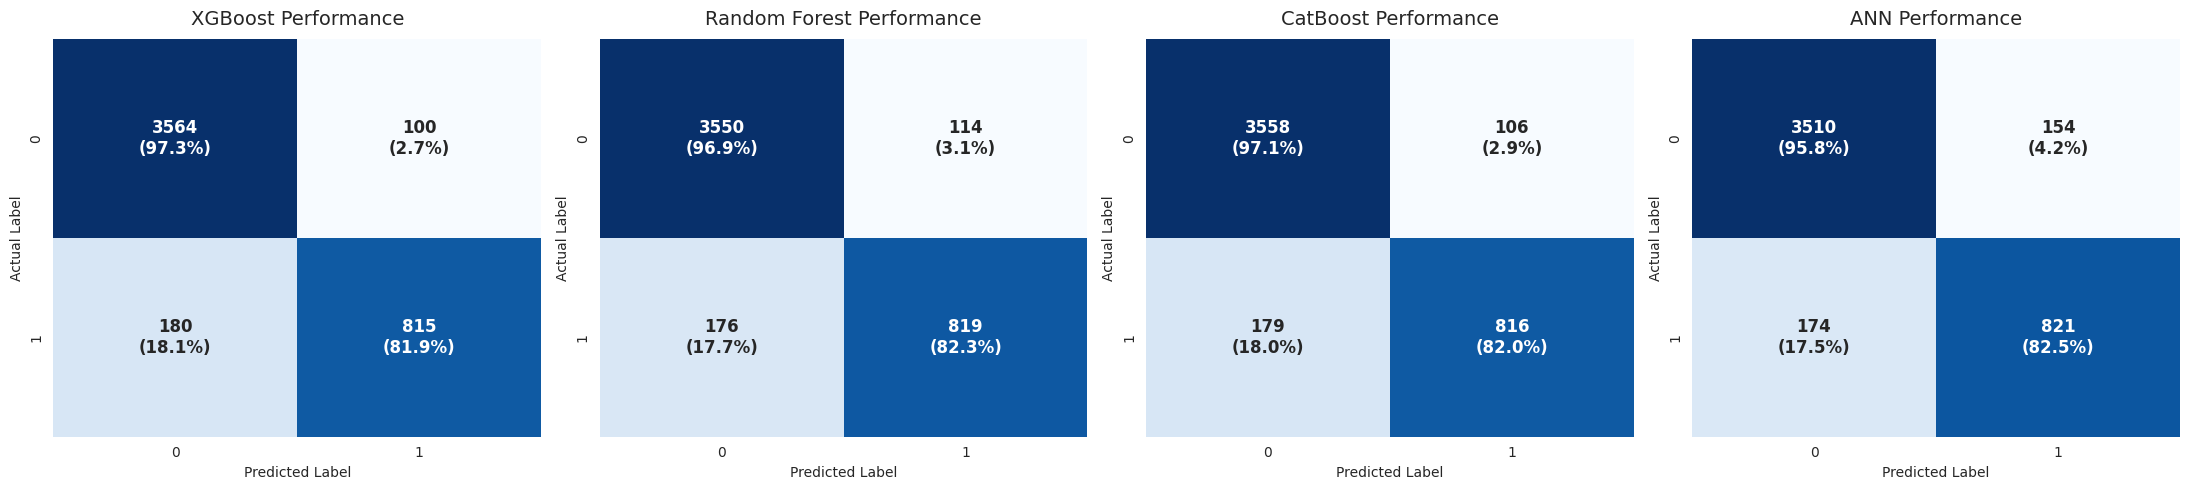

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

def plot_sub_confusion_matrix_dual(y_true, y_pred, title, ax):
    # คำนวณเมทริกซ์แบบจำนวนจริง (Original)
    cm = confusion_matrix(y_true, y_pred)

    # คำนวณเมทริกซ์แบบเปอร์เซ็นต์ (Normalization ตามแนวแถว/Actual)
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    # สร้าง Label ที่รวมทั้ง จำนวนจริง และ เปอร์เซ็นต์ เข้าด้วยกัน"
    labels = (np.array(["{0:d}\n({1:.1f}%)".format(count, perc)
              for count, perc in zip(cm.flatten(), cm_perc.flatten())]
             )).reshape(2, 2)

    # วาด Heatmap โดยใช้ cm_perc เป็นตัวกำหนดสี แต่ใช้ labels เป็นตัวเลขแสดงผล
    sns.heatmap(cm_perc, annot=labels, fmt='', cmap='Blues', ax=ax, cbar=False,
                annot_kws={"size": 12, "weight": "bold"})

    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

# สร้างพื้นที่สำหรับ 4 กราฟ (1 แถว 4 คอลัมน์)
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# รันฟังก์ชันสำหรับแต่ละโมเดล
plot_sub_confusion_matrix_dual(y_test, y_pred_xgb_tuned, 'XGBoost Performance', axes[0])
plot_sub_confusion_matrix_dual(y_test, y_pred_rf_tuned, 'Random Forest Performance', axes[1])
plot_sub_confusion_matrix_dual(y_test, y_pred_cat_tuned, 'CatBoost Performance', axes[2])
plot_sub_confusion_matrix_dual(y_test, y_pred_ANN, 'ANN Performance', axes[3])

plt.tight_layout()
plt.show()

### ROC Curve Comparison

146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


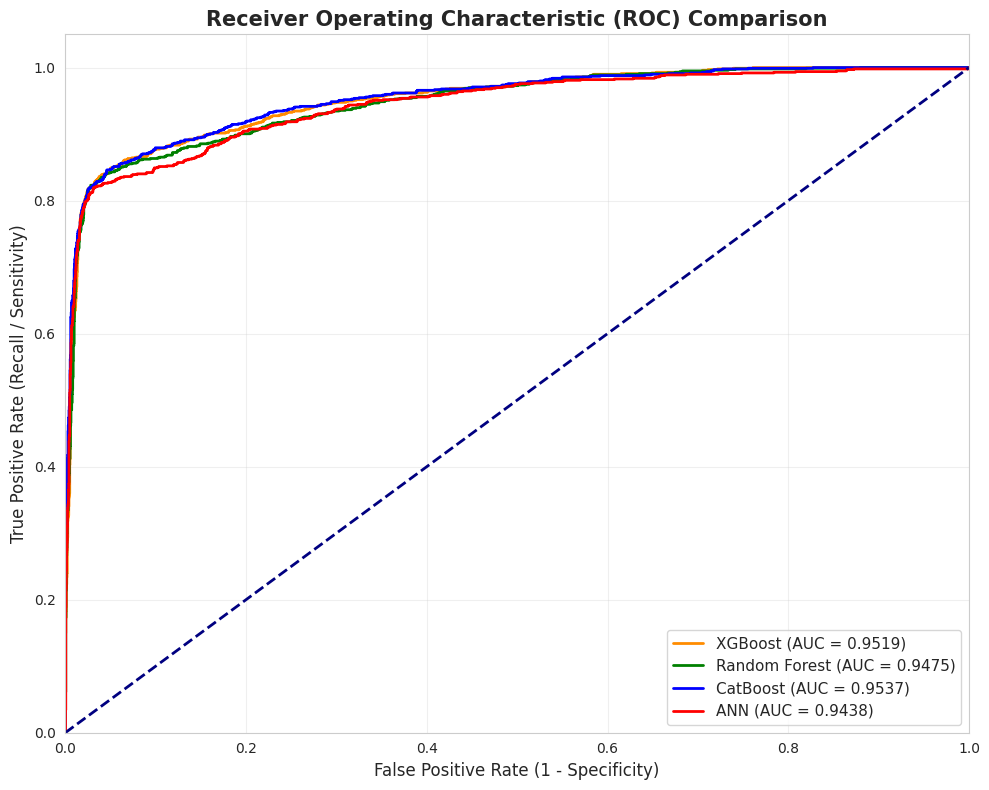

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# คำนวณค่า Probability ของคลาส 1 สำหรับแต่ละโมเดล
# หมายเหตุ: สำหรับ ANN ถ้าใช้ sigmoid ใน layer สุดท้ายใช้ y_pred_ANN_prob ตระกูล Tree ต้องใช้ .predict_proba()[:, 1]
probs = {
    'XGBoost': best_xgb.predict_proba(X_test)[:, 1],
    'Random Forest': best_rf.predict_proba(X_test)[:, 1],
    'CatBoost': best_cat.predict_proba(X_test)[:, 1],
    'ANN': model_ANN.predict(X_test).ravel()
}

plt.figure(figsize=(10, 8))
sns.set_style("whitegrid")

# สีสำหรับแต่ละเส้น
colors = ['darkorange', 'green', 'blue', 'red']
model_names = list(probs.keys())

# วนลูปเพื่อคำนวณ ROC และ AUC แล้วพล็อตกราฟ
for i, name in enumerate(model_names):
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, color=colors[i], lw=2,
             label=f'{name} (AUC = {roc_auc:.4f})')

# ลากเส้นตรงกลาง (Random Classifier Line)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Comparison', fontsize=15, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "roc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 8. Feature Importance Analysis


In [35]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score

features = X_train.columns

# Feature importance from tree-based models
xgb_importance = best_xgb.feature_importances_
rf_importance = best_rf.feature_importances_
cat_importance = best_cat.feature_importances_

# ANN permutation importance using the original 0.70 classification threshold
def ann_permutation_scorer(estimator, X, y_true):
    y_pred_proba = estimator.predict(X, verbose=0).ravel()
    y_pred_binary = (y_pred_proba > 0.70).astype(int)
    return accuracy_score(y_true, y_pred_binary)

result_ann = permutation_importance(
    model_ANN,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    n_jobs=1,
    scoring=ann_permutation_scorer
)
ann_importance = result_ann.importances_mean

importance_df = pd.DataFrame({
    "Feature": features,
    "XGBoost (Gain)": xgb_importance,
    "Random Forest (Gini)": rf_importance,
    "CatBoost (Weight)": cat_importance,
    "ANN (Permutation)": ann_importance
})

display(importance_df)


,Feature,XGBoost (Gain),Random Forest (Gini),CatBoost (Weight),ANN (Permutation)
0,BMI,0.017644,0.012397,3.094131,3.004937e-04
1,Gender,0.016984,0.001247,1.430163,-5.580597e-04
2,Age,0.037804,0.055966,3.565187,5.194248e-03
3,ICD10_Group_Chronic_Diseases,0.000000,0.000000,0.000126,4.292767e-05
4,ICD10_Group_Lymph_Node_TB,0.014918,0.003219,0.056866,2.189311e-02
5,ICD10_Group_Miliary_TB,0.006328,0.000445,0.021666,2.403949e-03
6,ICD10_Group_Nervous_System_TB,0.000000,0.005403,0.153448,5.838163e-03
7,ICD10_Group_Other_Extrapulmonary_TB,0.007125,0.000656,0.099192,2.391071e-02
8,ICD10_Group_Other_Respiratory_TB,0.000000,0.001320,0.118278,2.962009e-02
9,ICD10_Group_Pulmonary_TB,0.016307,0.002067,0.161010,4.876583e-02


### Normalized Feature Importance

,Feature,XGBoost (Gain),Random Forest (Gini),CatBoost (Weight),ANN (Permutation)
23,Duration,1.000000,1.000000,1.000000,1.000000
16,(TB F/U) follow up,0.495563,0.623044,0.462845,0.459097
2,Age,0.075822,0.104999,0.068016,0.034791
22,AFB resulf of first month,0.055741,0.007280,0.057036,0.023037
18,Chronic Kidney Disease,0.036013,0.025138,0.007866,0.007052
0,BMI,0.035388,0.023258,0.059029,0.007992
1,Gender,0.034065,0.002340,0.027283,0.003291
9,ICD10_Group_Pulmonary_TB,0.032707,0.003878,0.003069,0.273390
12,Cohort of TB,0.031327,0.002366,0.067376,0.012459
14,Treatment of ARV,0.031004,0.006525,0.019269,0.006347


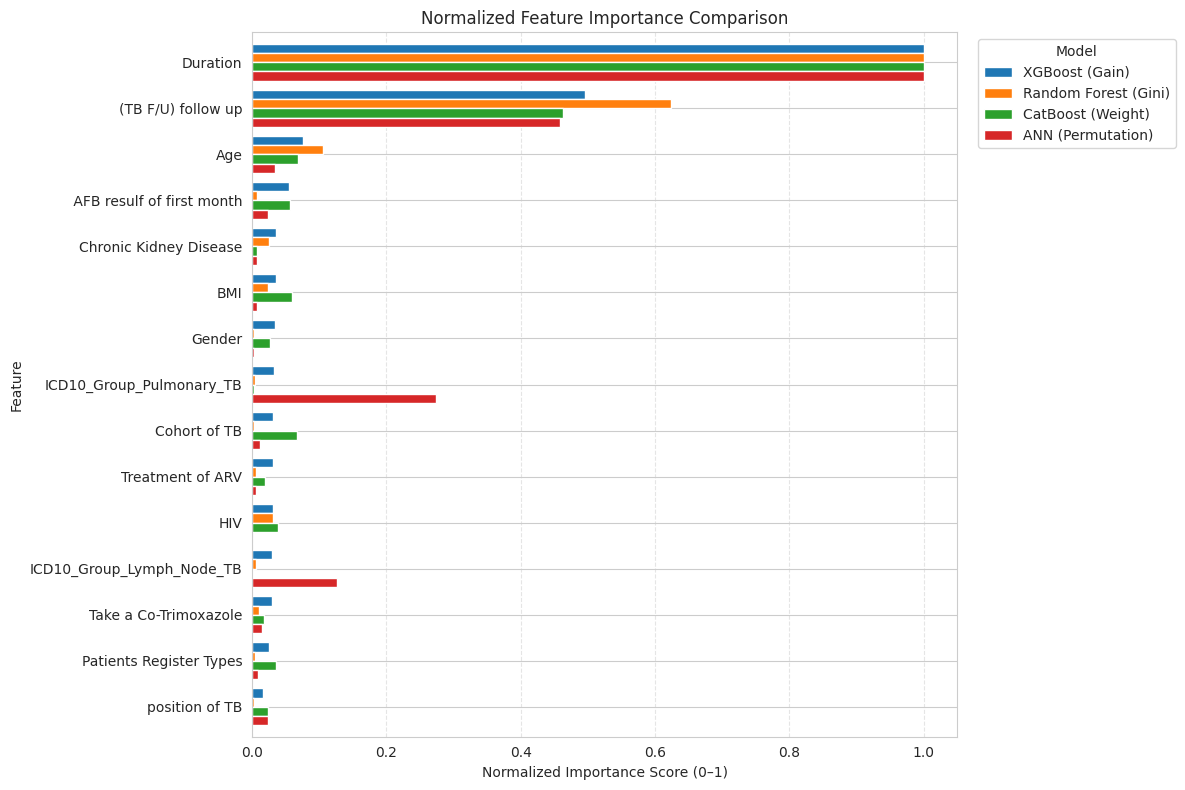

In [36]:
importance_df_norm = importance_df.copy()

importance_columns = [
    "XGBoost (Gain)",
    "Random Forest (Gini)",
    "CatBoost (Weight)",
    "ANN (Permutation)"
]

for col in importance_columns:
    min_val = importance_df_norm[col].min()
    max_val = importance_df_norm[col].max()
    if max_val != min_val:
        importance_df_norm[col] = (
            importance_df_norm[col] - min_val
        ) / (max_val - min_val)
    else:
        importance_df_norm[col] = 0.0

importance_df_norm = importance_df_norm.sort_values(
    by="XGBoost (Gain)",
    ascending=False
)

display(importance_df_norm)

plot_data = (
    importance_df_norm
    .head(15)
    .set_index("Feature")[importance_columns]
)

ax = plot_data.plot(
    kind="barh",
    figsize=(12, 8),
    width=0.8
)
ax.invert_yaxis()
plt.title("Normalized Feature Importance Comparison")
plt.xlabel("Normalized Importance Score (0–1)")
plt.ylabel("Feature")
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("feature_importance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
